##HYPOTHESIS - STL decomposition needs monthly NDVI data
STL decomposition may work better with monthly NDVI data vs the 16 day composite we have been using (REF?)
TO test this we are running a new set of code (provided by Co-pilot) and compare the monthly NDVI outcome with the 16 day composite outcome.



###Benefits of monthly NDVI
CLean 12 month seasonal cycle
Removes any issuse of irregular spacing
Eliminates blurred lines in some plots
Improves trend stability
Reduces edge artefacts e.g. if drought is near start or end of time series.
Recommends using monthly NDVI and STL with period = 12
Then compute deltaNDVI from window averages.
##Comparing monthly with 16 day NDVI
will answer following questions:
1. Is 16 day data introducing bias or instability (see plots)
2. DOes temporal aggregation change conclusions?
3/ Which sites are sensitive (usually those with small deltaNDVI)

###Step by step process
1. Helper STL and deltaNDVI functions

In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.seasonal import STL

def compute_delta_ndvi(series, period, pre_window, post_window,
                       drought_date,
                       seasonal, trend):

    # Ensure clean series
    series = series.sort_index().interpolate(limit_direction='both')

    # Run STL
    stl = STL(series, period=period,
              seasonal=seasonal,
              trend=trend,
              robust=True)
    res = stl.fit()
    trend_comp = res.trend

    # Extract windows
    pre_vals = trend_comp.loc[pre_window[0]:pre_window[1]]
    post_vals = trend_comp.loc[post_window[0]:post_window[1]]

    # Compute delta (mean-based = robust)
    delta = post_vals.mean() - pre_vals.mean()

    return delta, trend_comp


Site level comparison function

In [2]:
def compare_16day_vs_monthly(df, drought_date,
                            pre_window, post_window):

    # ---- 16-DAY SERIES ----
    df_16 = df.copy()
    df_16 = df_16.set_index('date').sort_index()

    delta_16, trend_16 = compute_delta_ndvi(
        df_16['NDVI'], # Changed from 'ndvi' to 'NDVI'
        period=23,          # ~annual cycle
        seasonal=23,
        trend=47,
        drought_date=drought_date,
        pre_window=pre_window,
        post_window=post_window
    )

    # ---- MONTHLY SERIES ----
    df_monthly = df_16['NDVI'].resample('ME').mean() # Changed from 'ndvi' to 'NDVI'

    delta_month, trend_month = compute_delta_ndvi(
        df_monthly,
        period=12,
        seasonal=13,
        trend=25,
        drought_date=drought_date,
        pre_window=pre_window,
        post_window=post_window
    )

    return {
        'delta_16day': delta_16,
        'delta_monthly': delta_month,
        'difference': delta_month - delta_16
    }

Run across multiple sites

In [3]:
# Define a placeholder site_dict
# In a real scenario, you would load your site data into this dictionary.
# Each key would be a site name, and each value would be a pandas DataFrame
# containing at least 'date' and 'ndvi' columns.

site_dict = {
    'Tue': pd.DataFrame({
        'date': pd.to_datetime(pd.date_range(start='2015-01-01', periods=100, freq='16D')),
        'ndvi': np.random.rand(100)
    }),
    'Vog': pd.DataFrame({
        'date': pd.to_datetime(pd.date_range(start='2015-01-01', periods=100, freq='16D')),
        'ndvi': np.random.rand(100) * 0.8 + 0.1 # slightly different NDVI values
    })
}


Once your Drive is mounted, you can load your CSV file. Make sure to update the file path to where your `master_dataframe_v2_geo.csv` is located in your Google Drive.

In [4]:
# Replace 'path/to/your/master_dataframe_v2_geo.csv' with the actual path in your Google Drive
file_path = '/content/drive/MyDrive/master_dataframe_v2_geo.csv'
master_df = pd.read_csv(file_path)

# Display the first few rows and information about the loaded dataframe
display(master_df.head())
display(master_df.info())

/tmp/ipykernel_591/219337038.py:3: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  master_df = pd.read_csv(file_path)


,plot_id,date,NDVI,trend,residual,year,doy,Country,site_id,Event_date,...,time_since_drought_end,plot_id_clean,plot_id_std,Lat_x,Long_x,final_join_key,Lat_y,Long_y,Lat,Long
0,Wald_mort,2000-02-18,0.6659,0.839130,-0.117425,2000,49,Germany,Germany_Wald_mort,2020.0,...,NaN,wald_mort,Wald_mort,47.684,8.169,wald_mort,47.684,8.169,47.684,8.169
1,Wald_mort,2000-03-05,0.8074,0.832875,0.112856,2000,65,Germany,Germany_Wald_mort,2020.0,...,NaN,wald_mort,Wald_mort,47.684,8.169,wald_mort,47.684,8.169,47.684,8.169
2,Wald_mort,2000-03-21,0.6831,0.826667,-0.038126,2000,81,Germany,Germany_Wald_mort,2020.0,...,NaN,wald_mort,Wald_mort,47.684,8.169,wald_mort,47.684,8.169,47.684,8.169
3,Wald_mort,2000-04-06,0.7950,0.820510,0.189651,2000,97,Germany,Germany_Wald_mort,2020.0,...,NaN,wald_mort,Wald_mort,47.684,8.169,wald_mort,47.684,8.169,47.684,8.169
4,Wald_mort,2000-04-22,0.7822,0.814410,0.068412,2000,113,Germany,Germany_Wald_mort,2020.0,...,NaN,wald_mort,Wald_mort,47.684,8.169,wald_mort,47.684,8.169,47.684,8.169


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196139 entries, 0 to 196138
Data columns (total 34 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   plot_id                   196139 non-null  object 
 1   date                      196139 non-null  object 
 2   NDVI                      195425 non-null  float64
 3   trend                     176227 non-null  float64
 4   residual                  176227 non-null  float64
 5   year                      196139 non-null  int64  
 6   doy                       196139 non-null  int64  
 7   Country                   119783 non-null  object 
 8   site_id                   119783 non-null  object 
 9   Event_date                119783 non-null  object 
 10  Climate                   119783 non-null  object 
 11  Forest_type               119783 non-null  object 
 12  Quality                   119783 non-null  object 
 13  %_Mort                    119783 non-null  f

None

Now, we will transform the `master_df` into the `site_dict` format. This assumes your `master_df` has columns for 'site_name', 'date', and 'ndvi'. Adjust these column names if they are different in your CSV file.

In [5]:
# Ensure the 'date' column is in datetime format
master_df['date'] = pd.to_datetime(master_df['date'])

# Create the site_dict from the master_df
# Assuming your DataFrame has a 'plot_id' column to group by, and 'NDVI' as the NDVI column
site_dict = {
    site_name: site_df[['date', 'NDVI']].copy()  # Use 'NDVI' and 'plot_id'
    for site_name, site_df in master_df.groupby('plot_id')
}

print(f"Created site_dict with {len(site_dict)} sites.")
# Display a sample entry from the new site_dict
if site_dict:
    first_site_name = list(site_dict.keys())[0]
    print(f"First site in site_dict: {first_site_name}")
    display(site_dict[first_site_name].head())

Created site_dict with 167 sites.
First site in site_dict: AGP2


,date,NDVI
85203,2000-02-18,0.2117
85204,2000-03-05,0.5364
85205,2000-03-21,0.7496
85206,2000-04-06,0.8487
85207,2000-04-22,0.5331


In [6]:
results = []

for site_name, df in site_dict.items():

    res = compare_16day_vs_monthly(
        df,
        drought_date='2018-04-01',  # adjust
        pre_window=('2016-01-01', '2018-01-01'),
        post_window=('2019-01-01', '2021-01-01')
    )

    res['site'] = site_name
    results.append(res)

results_df = pd.DataFrame(results)

Inspect results

In [7]:
print(results_df)

     delta_16day  delta_monthly  difference      site
0       0.004477       0.001546   -0.002931      AGP2
1       0.052478       0.046403   -0.006075      Akam
2       0.070103       0.070418    0.000315  Albatera
3       0.009810       0.018766    0.008955   Arcalis
4      -0.000108       0.032722    0.032830      BNT4
..           ...            ...         ...       ...
162     0.007762       0.048814    0.041052        kc
163    -0.002584      -0.020322   -0.017738     pasoh
164     0.034983       0.034386   -0.000597         x
165     0.023548       0.022721   -0.000827         y
166    -0.025213       0.033436    0.058649    yasuni

[167 rows x 4 columns]


Visualise the comparison

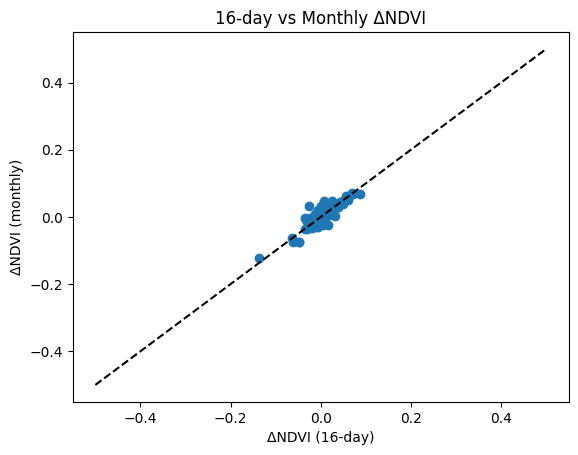

In [8]:
import matplotlib.pyplot as plt

plt.scatter(results_df['delta_16day'],
            results_df['delta_monthly'])

plt.plot([-0.5, 0.5], [-0.5, 0.5], 'k--')  # 1:1 line

plt.xlabel('ΔNDVI (16-day)')
plt.ylabel('ΔNDVI (monthly)')
plt.title('16-day vs Monthly ΔNDVI')

plt.show()

### Sites with the Largest Difference

In [9]:
results_df['abs_difference'] = results_df['difference'].abs()
largest_diff_sites = results_df.sort_values(by='abs_difference', ascending=False).head(10)
display(largest_diff_sites.drop(columns=['abs_difference']))

,delta_16day,delta_monthly,difference,site
166,-0.025213,0.033436,0.058649,yasuni
127,0.016738,-0.024817,-0.041555,TEC2
162,0.007762,0.048814,0.041052,kc
129,0.008340,0.041675,0.033336,TEM5
19,-0.035262,-0.002082,0.033181,CO
4,-0.000108,0.032722,0.032830,BNT4
79,0.009968,-0.021844,-0.031812,Roo
69,0.004267,-0.025513,-0.029780,Ober
125,0.004097,0.033299,0.029203,TAM8
35,0.031583,0.002622,-0.028961,Denny


### Exporting Results

In [10]:
# Define the export path within your Google Drive
output_file_path = '/content/drive/MyDrive/DeltaNDVI/delta_ndvi_comparison.csv'

# Export the results_df to a CSV file
results_df.to_csv(output_file_path, index=False)

print(f"Results exported successfully to: {output_file_path}")

Results exported successfully to: /content/drive/MyDrive/DeltaNDVI/delta_ndvi_comparison.csv


### Visualizing STL Trend Decomposition for Specific Sites

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import os

target_sites = ['Fich', 'Tue', 'Hass', 'Wald_mort', 'Harz_mort', 'Vog', 'Gro', 'AGP2', 'TEC6']

# Dynamically define site-specific parameters from master_df
dynamic_site_parameters = {}
# Ensure the 'Event_date', 'start_date', 'end_date' columns in master_df are datetime objects
master_df['Event_date'] = pd.to_datetime(master_df['Event_date'], errors='coerce')
master_df['start_date'] = pd.to_datetime(master_df['start_date'], errors='coerce')
master_df['end_date'] = pd.to_datetime(master_df['end_date'], errors='coerce')

# Define a default set of parameters as a fallback
default_params = {
    'drought_date': '2018-04-01',
    'pre_window': ('2016-01-01', '2018-01-01'),
    'post_window': ('2019-01-01', '2021-01-01')
}

unique_plot_ids_in_master = master_df['plot_id'].unique()

for pid in unique_plot_ids_in_master:
    # Filter for the current plot_id and drop rows where any of the key date columns are missing
    site_drought_info = master_df[master_df['plot_id'] == pid].dropna(subset=['Event_date', 'start_date', 'end_date'])

    if not site_drought_info.empty:
        # Take the first available set of drought dates for the plot_id
        # Assuming Event_date, start_date, end_date are consistent for a plot_id or the first one is representative
        first_drought_event = site_drought_info.iloc[0]

        drought_date_dt = first_drought_event['Event_date']
        drought_start_dt = first_drought_event['start_date']
        drought_end_dt = first_drought_event['end_date']

        # Construct pre and post windows
        # Pre-drought window: 2 years before drought_start, ending at drought_start
        pre_window_start = drought_start_dt - pd.DateOffset(years=2)
        pre_window_end = drought_start_dt

        # Post-drought window: 2 years after drought_end, starting at drought_end
        post_window_start = drought_end_dt
        post_window_end = drought_end_dt + pd.DateOffset(years=2)

        dynamic_site_parameters[pid] = {
            'drought_date': drought_date_dt.strftime('%Y-%m-%d'),
            'pre_window': (pre_window_start.strftime('%Y-%m-%d'), pre_window_end.strftime('%Y-%m-%d')),
            'post_window': (post_window_start.strftime('%Y-%m-%d'), post_window_end.strftime('%Y-%m-%d'))
        }
    # If no valid drought dates are found for a plot_id, it will implicitly use `default_params` later.

found_sites_data = {}

for site_name in target_sites:
    # Get parameters for the current site, preferring dynamic ones, then default
    params = dynamic_site_parameters.get(site_name, default_params)
    current_drought_date = params['drought_date']
    current_pre_window = params['pre_window']
    current_post_window = params['post_window']

    if site_name in site_dict:
        df_site = site_dict[site_name].copy()

        # --- 16-DAY SERIES ---
        df_16 = df_site.set_index('date').sort_index()
        df_16['NDVI_interp'] = df_16['NDVI'].interpolate(method='linear', limit_direction='both', limit_area='inside')

        if df_16['NDVI_interp'].isnull().all():
            print(f"Skipping site {site_name}: All NDVI values are NaN after interpolation for 16-day series.")
            continue

        delta_16, trend_16 = compute_delta_ndvi(
            df_16['NDVI_interp'],
            period=23,
            seasonal=23,
            trend=171,  #~7.5 yrs, changed from 91
            drought_date=current_drought_date,
            pre_window=current_pre_window,
            post_window=current_post_window
        )

        # --- MONTHLY SERIES ---
        df_monthly_resampled = df_16['NDVI'].resample('ME').mean()
        df_monthly_resampled_interp = df_monthly_resampled.interpolate(method='linear', limit_direction='both', limit_area='inside')

        if df_monthly_resampled_interp.isnull().all():
            print(f"Skipping site {site_name}: All NDVI values are NaN after interpolation for monthly series.")
            continue

        delta_month, trend_month = compute_delta_ndvi(
            df_monthly_resampled_interp,
            period=12,
            seasonal=13,
            trend=61, #~5yrs, changed from 37
            drought_date=current_drought_date,
            pre_window=current_pre_window,
            post_window=current_post_window
        )

        found_sites_data[site_name] = {
            'df_16': df_16,
            'trend_16': trend_16,
            'delta_16': delta_16,
            'df_monthly_resampled': df_monthly_resampled,
            'trend_month': trend_month,
            'delta_month': delta_month
        }
    else:
        print(f"Site '{site_name}' not found in site_dict.")

# Define the directory to save plots
plot_output_dir = '/content/drive/MyDrive/v2_New plots/'
os.makedirs(plot_output_dir, exist_ok=True)

# Now plot for each found site
for site_name, data in found_sites_data.items():
    fig, ax = plt.subplots(figsize=(15, 7))

    # Get the correct drought date and windows for plotting (already determined above)
    params = dynamic_site_parameters.get(site_name, default_params) # Re-fetch to ensure consistency if needed
    plot_drought_date = params['drought_date']
    plot_pre_window = params['pre_window']
    plot_post_window = params['post_window']

    # 16-day Trend
    ax.plot(data['trend_16'].index, data['trend_16'], '-', color='red', linewidth=2, label='16-day STL Trend')

    # Monthly Trend
    ax.plot(data['trend_month'].index, data['trend_month'], '-', color='blue', linewidth=2, label='Monthly STL Trend')

    # Combine all relevant trend data for y-axis limits
    all_trend_values = pd.concat([data['trend_16'], data['trend_month']])
    min_y_val = all_trend_values.min()
    max_y_val = all_trend_values.max()
    padding = (max_y_val - min_y_val) * 0.05 # 5% padding
    ax.set_ylim(min_y_val - padding, max_y_val + padding)

    # Ensure pre_window and post_window are within the actual data range
    # This is handled by ensuring the data series itself does not contain dates outside the desired range
    # If the user means to restrict the plotting X-axis, we need to find the overall min/max dates of the actual data
    overall_min_date = data['trend_16'].index.min()
    overall_max_date = data['trend_16'].index.max()

    # Set x-axis limits to roughly 2000-2025, clipped by actual data range
    start_plot_date = max(pd.to_datetime('2000-01-01'), overall_min_date)
    end_plot_date = min(pd.to_datetime('2025-12-31'), overall_max_date)
    ax.set_xlim(start_plot_date, end_plot_date)

    # Highlight pre and post windows
    # Ensure the plotted areas are within the current x-axis limits
    ax.axvspan(pd.to_datetime(plot_pre_window[0]), pd.to_datetime(plot_pre_window[1]), color='green', alpha=0.1, label='Pre-Drought Window')
    ax.axvspan(pd.to_datetime(plot_post_window[0]), pd.to_datetime(plot_post_window[1]), color='orange', alpha=0.1, label='Post-Drought Window')

    # Drought date
    ax.axvline(pd.to_datetime(plot_drought_date), color='grey', linestyle='--', label='Drought Date')

    # --- Add annotations for pre/post means and deltaNDVI ---
    pre_vals_16 = data['trend_16'].loc[pd.to_datetime(plot_pre_window[0]):pd.to_datetime(plot_pre_window[1])]
    post_vals_16 = data['trend_16'].loc[pd.to_datetime(plot_post_window[0]):pd.to_datetime(plot_post_window[1])]
    mean_pre_16 = pre_vals_16.mean()
    mean_post_16 = post_vals_16.mean()

    pre_vals_month = data['trend_month'].loc[pd.to_datetime(plot_pre_window[0]):pd.to_datetime(plot_pre_window[1])]
    post_vals_month = data['trend_month'].loc[pd.to_datetime(plot_post_window[0]):pd.to_datetime(plot_post_window[1])]
    mean_pre_month = pre_vals_month.mean()
    mean_post_month = post_vals_month.mean()

    # Plot 16-day pre/post points at the trend line boundaries
    ax.plot(pd.to_datetime(plot_pre_window[0]), data['trend_16'].asof(pd.to_datetime(plot_pre_window[0])), 'o', color='red', markersize=8)
    ax.plot(pd.to_datetime(plot_post_window[1]), data['trend_16'].asof(pd.to_datetime(plot_post_window[1])), 'o', color='red', markersize=8)

    # Plot monthly pre/post points at the trend line boundaries
    ax.plot(pd.to_datetime(plot_pre_window[0]), data['trend_month'].asof(pd.to_datetime(plot_pre_window[0])), 'D', color='blue', markersize=8)
    ax.plot(pd.to_datetime(plot_post_window[1]), data['trend_month'].asof(pd.to_datetime(plot_post_window[1])), 'D', color='blue', markersize=8)


    ax.set_title(f'NDVI Trends for Site: {site_name}')
    ax.set_xlabel('Date')
    ax.set_ylabel('NDVI')

    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    ax.text(xmax * 0.95, ymin + (ymax - ymin) * 0.05, f'Δ16D: {data['delta_16']:.3f}',
            color='red', horizontalalignment='right', verticalalignment='bottom', fontsize=10)
    ax.text(xmax * 0.95, ymin + (ymax - ymin) * 0.10, f'ΔM: {data['delta_month']:.3f}',
            color='blue', horizontalalignment='right', verticalalignment='bottom', fontsize=10)

    ax.legend(loc='upper left')
    plt.grid(True)
    plt.tight_layout()

    file_name = f"{site_name}_delta_ndvi_individual_plot.png"
    save_path = os.path.join(plot_output_dir, file_name)
    plt.savefig(save_path)
    print(f"Plot saved to: {save_path}")
    plt.close(fig) # Close the figure to free up memory

Plot saved to: /content/drive/MyDrive/v2_New plots/Fich_delta_ndvi_individual_plot.png
Plot saved to: /content/drive/MyDrive/v2_New plots/Tue_delta_ndvi_individual_plot.png
Plot saved to: /content/drive/MyDrive/v2_New plots/Hass_delta_ndvi_individual_plot.png
Plot saved to: /content/drive/MyDrive/v2_New plots/Wald_mort_delta_ndvi_individual_plot.png
Plot saved to: /content/drive/MyDrive/v2_New plots/Harz_mort_delta_ndvi_individual_plot.png
Plot saved to: /content/drive/MyDrive/v2_New plots/Vog_delta_ndvi_individual_plot.png
Plot saved to: /content/drive/MyDrive/v2_New plots/Gro_delta_ndvi_individual_plot.png
Plot saved to: /content/drive/MyDrive/v2_New plots/AGP2_delta_ndvi_individual_plot.png
Plot saved to: /content/drive/MyDrive/v2_New plots/TEC6_delta_ndvi_individual_plot.png


### Calculated Delta NDVI Differences for Specific Sites

In [12]:
specific_site_deltas = []

for site_name, data in found_sites_data.items():
    specific_site_deltas.append({
        'site': site_name,
        'delta_16day': data['delta_16'],
        'delta_monthly': data['delta_month'],
        'difference': data['delta_month'] - data['delta_16']
    })

specific_site_deltas_df = pd.DataFrame(specific_site_deltas)
display(specific_site_deltas_df)

,site,delta_16day,delta_monthly,difference
0,Fich,0.001079,-0.014199,-0.015277
1,Tue,-0.016903,0.003601,0.020504
2,Hass,-0.002419,-0.007488,-0.005069
3,Wald_mort,-0.030923,-0.051707,-0.020784
4,Harz_mort,-0.150512,-0.160793,-0.010281
5,Vog,-0.017488,-0.006274,0.011214
6,Gro,-0.001247,0.003117,0.004364
7,AGP2,-0.000899,0.023249,0.024148
8,TEC6,0.044354,0.033883,-0.010470


### Investigating Anomalous Sites with Monthly NDVI

To check if the anomalous sites (positive residuals in deltaNDVI vs %_Mort, and mixed forest type) are consistent with monthly NDVI data, we'll first merge the `specific_site_deltas_df` with relevant metadata from the `master_df` (Forest Type and % Mortality). Then, we will plot the `delta_monthly` against `%_Mort`, and identify sites matching the criteria.

In [13]:
# Extract unique Forest_type and %_Mort for each plot_id from master_df
# Assuming Forest_type and %_Mort are constant for a given plot_id
site_metadata = master_df[['plot_id', 'Forest_type', '%_Mort']].drop_duplicates(subset=['plot_id']).set_index('plot_id')

# Rename 'site' column to 'plot_id' in results_df for merging (using all 167 sites)
results_df_merged = results_df.rename(columns={'site': 'plot_id'})

# Merge the delta results with the site metadata
merged_analysis_df = pd.merge(
    results_df_merged,
    site_metadata,
    on='plot_id',
    how='left'
)

# Drop rows where %_Mort is NaN, as it's needed for the analysis
merged_analysis_df = merged_analysis_df.dropna(subset=['%_Mort'])

display(merged_analysis_df.head())

,delta_16day,delta_monthly,difference,plot_id,abs_difference,Forest_type,%_Mort
0,0.004477,0.001546,-0.002931,AGP2,0.002931,Mixed,19.0
1,0.052478,0.046403,-0.006075,Akam,0.006075,Conifer,21.0
2,0.070103,0.070418,0.000315,Albatera,0.000315,Conifer,18.0
4,-0.000108,0.032722,0.032830,BNT4,0.032830,Mixed,1.0
5,0.017019,0.025359,0.008339,BNT7,0.008339,Mixed,1.0


#### Plotting Monthly Delta NDVI vs. % Mortality for ALL 167 Sites

Plot saved to: /content/drive/MyDrive/New plots/all_167_sites_monthly_delta_ndvi_mortality.png


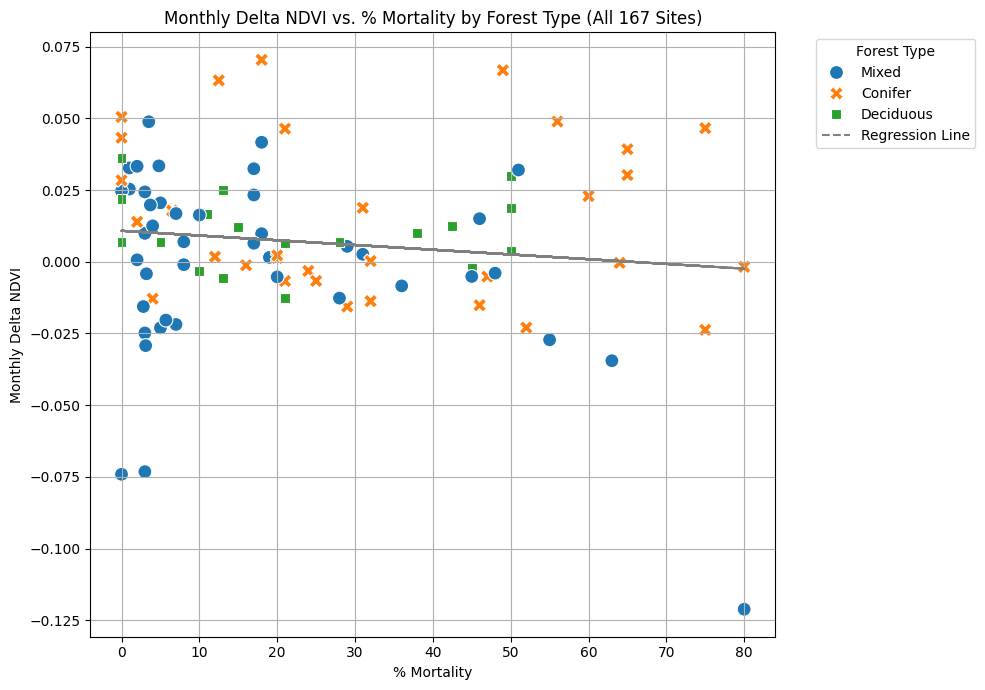

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import os

plt.figure(figsize=(10, 7))

# Create the scatter plot for all 167 sites
sns.scatterplot(
    data=merged_analysis_df,
    x='%_Mort',
    y='delta_monthly',
    hue='Forest_type', # Color points by Forest_type
    style='Forest_type', # Use different markers for Forest_type
    s=100 # Adjust size for better visibility
)

# Fit a linear regression model
X_all = merged_analysis_df[['%_Mort']]
y_all = merged_analysis_df['delta_monthly']
model_all = LinearRegression()
model_all.fit(X_all, y_all)

# Add the regression line to the plot
plt.plot(X_all, model_all.predict(X_all), color='gray', linestyle='--', label='Regression Line')

plt.title('Monthly Delta NDVI vs. % Mortality by Forest Type (All 167 Sites)')
plt.xlabel('% Mortality')
plt.ylabel('Monthly Delta NDVI')
plt.grid(True)
plt.legend(title='Forest Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Save the plot
plot_output_dir = '/content/drive/MyDrive/New plots/'
os.makedirs(plot_output_dir, exist_ok=True)
file_name = "all_167_sites_monthly_delta_ndvi_mortality.png"
save_path = os.path.join(plot_output_dir, file_name)
plt.savefig(save_path)
print(f"Plot saved to: {save_path}")
plt.show()

#### Calculating Residuals and Identifying Anomalous Sites for ALL 167 Sites

In [15]:
# Calculate residuals using the model fitted on all 167 sites
merged_analysis_df['predicted_delta_monthly_all_sites'] = model_all.predict(merged_analysis_df[['%_Mort']])
merged_analysis_df['residual_all_sites'] = merged_analysis_df['delta_monthly'] - merged_analysis_df['predicted_delta_monthly_all_sites']

# Identify anomalous sites: mixed forest_type and positive residual
anomalous_sites_monthly_all_sites = merged_analysis_df[
    (merged_analysis_df['Forest_type'] == 'Mixed') & # Ensure 'Mixed' matches actual data capitalization if case-sensitive
    (merged_analysis_df['residual_all_sites'] > 0)
]

print("Anomalous Sites (Mixed Forest Type, Positive Residuals) with Monthly NDVI (All 167 Sites):")
display(anomalous_sites_monthly_all_sites[['plot_id', 'delta_monthly', '%_Mort', 'Forest_type', 'residual_all_sites']])

Anomalous Sites (Mixed Forest Type, Positive Residuals) with Monthly NDVI (All 167 Sites):


,plot_id,delta_monthly,%_Mort,Forest_type,residual_all_sites
4,BNT4,0.032722,1.0,Mixed,0.022082
5,BNT7,0.025359,1.0,Mixed,0.014718
9,Bla,0.024642,0.0,Mixed,0.013836
20,CUZ1,0.009793,18.0,Mixed,0.001958
21,CUZ3,0.020546,5.0,Mixed,0.010565
62,M2,0.032011,51.0,Mixed,0.029622
64,Mach,0.015022,46.0,Mixed,0.011807
78,RES6,0.032434,17.0,Mixed,0.024434
117,Spess,0.016808,7.0,Mixed,0.007157
123,TAM6,0.024355,3.0,Mixed,0.014044


#### Distribution of Residuals for Anomalous Sites

Plot saved to: /content/drive/MyDrive/New plots/anomalous_sites_residuals_distribution.png


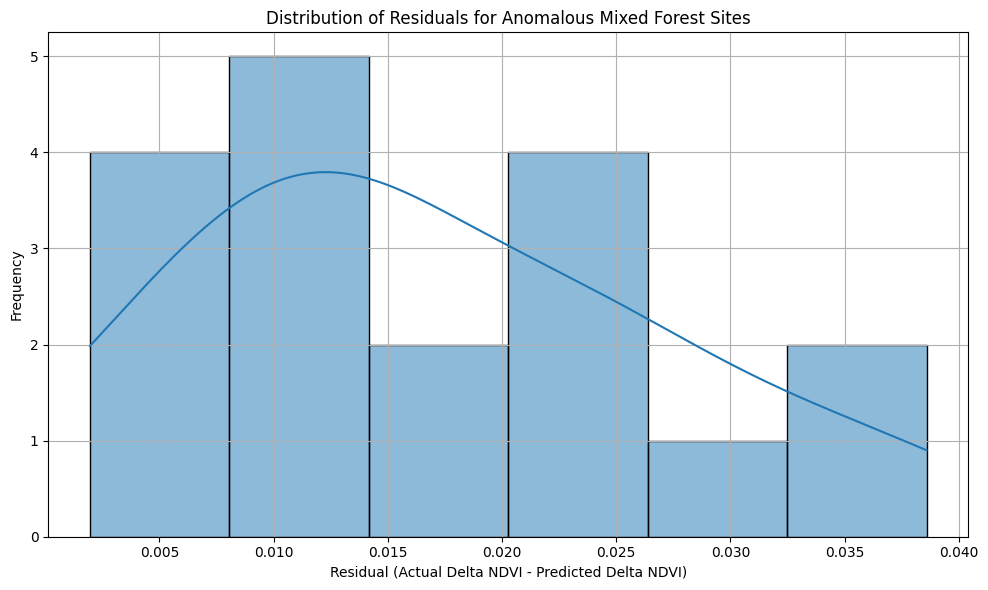

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd # Import pandas
from sklearn.linear_model import LinearRegression

# Recalculate residuals and anomalous sites to ensure variable is defined
# These lines are duplicated from b4e23bae and cbe1d2a4 to ensure self-containment for this cell

# --- Start of merged_analysis_df recreation ---
# Extract unique Forest_type and %_Mort for each plot_id from master_df
site_metadata = master_df[['plot_id', 'Forest_type', '%_Mort']].drop_duplicates(subset=['plot_id']).set_index('plot_id')

# Rename 'site' column to 'plot_id' in results_df for merging
results_df_merged = results_df.rename(columns={'site': 'plot_id'})

# Merge the delta results with the site metadata
merged_analysis_df = pd.merge(
    results_df_merged,
    site_metadata,
    on='plot_id',
    how='left'
)

# Drop rows where %_Mort is NaN, as it's needed for the analysis
merged_analysis_df = merged_analysis_df.dropna(subset=['%_Mort'])
# --- End of merged_analysis_df recreation ---

# Define X_all and y_all for model fitting
X_all = merged_analysis_df[['%_Mort']]
y_all = merged_analysis_df['delta_monthly']

# Re-fit the linear regression model 'model_all'
model_all = LinearRegression()
model_all.fit(X_all, y_all)

merged_analysis_df['predicted_delta_monthly_all_sites'] = model_all.predict(merged_analysis_df[['%_Mort']])
merged_analysis_df['residual_all_sites'] = merged_analysis_df['delta_monthly'] - merged_analysis_df['predicted_delta_monthly_all_sites']
anomalous_sites_monthly_all_sites = merged_analysis_df[
    (merged_analysis_df['Forest_type'] == 'Mixed') &
    (merged_analysis_df['residual_all_sites'] > 0)
]

if not anomalous_sites_monthly_all_sites.empty:
    plt.figure(figsize=(10, 6))
    sns.histplot(anomalous_sites_monthly_all_sites['residual_all_sites'], kde=True)
    plt.title('Distribution of Residuals for Anomalous Mixed Forest Sites')
    plt.xlabel('Residual (Actual Delta NDVI - Predicted Delta NDVI)')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.tight_layout()

    # Save the plot
    plot_output_dir = '/content/drive/MyDrive/New plots/'
    os.makedirs(plot_output_dir, exist_ok=True)
    file_name = "anomalous_sites_residuals_distribution.png"
    save_path = os.path.join(plot_output_dir, file_name)
    plt.savefig(save_path)
    print(f"Plot saved to: {save_path}")
    plt.show()
else:
    print("No anomalous sites to plot residuals for.")

#### Plotting Monthly Delta NDVI vs. % Mortality

Now, let's visualize the relationship between `delta_monthly` and `%_Mort`. We will also perform a simple linear regression to help identify sites with 'positive residuals'.

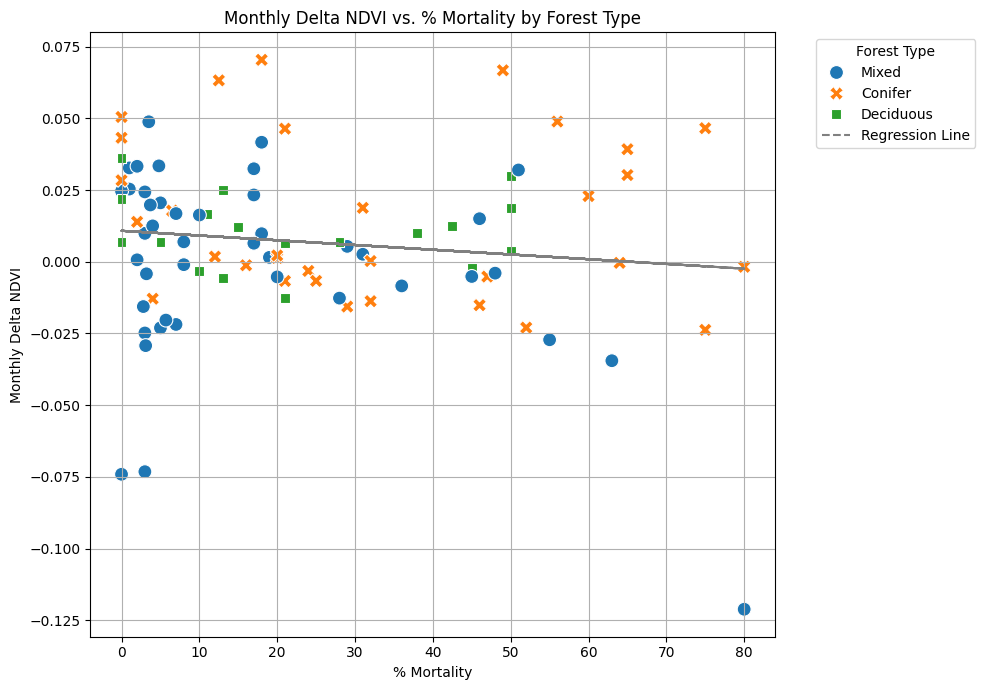

In [17]:
import seaborn as sns
from sklearn.linear_model import LinearRegression

plt.figure(figsize=(10, 7))

# Create the scatter plot
sns.scatterplot(
    data=merged_analysis_df,
    x='%_Mort',
    y='delta_monthly',
    hue='Forest_type', # Color points by Forest_type
    style='Forest_type', # Use different markers for Forest_type
    s=100 # Adjust size for better visibility
)

# Fit a linear regression model
X = merged_analysis_df[['%_Mort']]
y = merged_analysis_df['delta_monthly']
model = LinearRegression()
model.fit(X, y)

# Add the regression line to the plot
plt.plot(X, model.predict(X), color='gray', linestyle='--', label='Regression Line')

plt.title('Monthly Delta NDVI vs. % Mortality by Forest Type')
plt.xlabel('% Mortality')
plt.ylabel('Monthly Delta NDVI')
plt.grid(True)
plt.legend(title='Forest Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Rerunning Plot for all sites

Plot saved to: /content/drive/MyDrive/New plots/all_sites_monthly_delta_ndvi_mortality.png


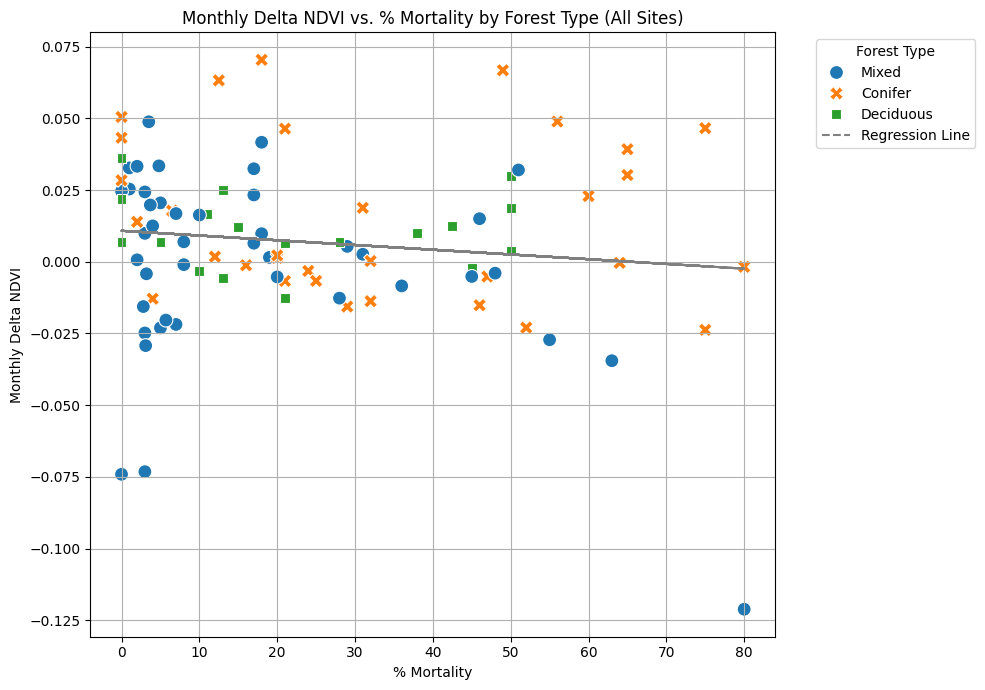

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import os

plt.figure(figsize=(10, 7))

# Create the scatter plot for all sites (rerun of previous plot)
sns.scatterplot(
    data=merged_analysis_df,
    x='%_Mort',
    y='delta_monthly',
    hue='Forest_type', # Color points by Forest_type
    style='Forest_type', # Use different markers for Forest_type
    s=100 # Adjust size for better visibility
)

# Fit a linear regression model
X = merged_analysis_df[['%_Mort']]
y = merged_analysis_df['delta_monthly']
model = LinearRegression()
model.fit(X, y)

# Add the regression line to the plot
plt.plot(X, model.predict(X), color='gray', linestyle='--', label='Regression Line')

plt.title('Monthly Delta NDVI vs. % Mortality by Forest Type (All Sites)')
plt.xlabel('% Mortality')
plt.ylabel('Monthly Delta NDVI')
plt.grid(True)
plt.legend(title='Forest Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Save the plot
plot_output_dir = '/content/drive/MyDrive/New plots/'
os.makedirs(plot_output_dir, exist_ok=True)
file_name = "all_sites_monthly_delta_ndvi_mortality.png"
save_path = os.path.join(plot_output_dir, file_name)
plt.savefig(save_path)
print(f"Plot saved to: {save_path}")
plt.show()

#### Plotting Monthly Delta NDVI vs. % Mortality by Individual Forest Type

Plot saved to: /content/drive/MyDrive/New plots/Mixed_monthly_delta_ndvi_mortality.png


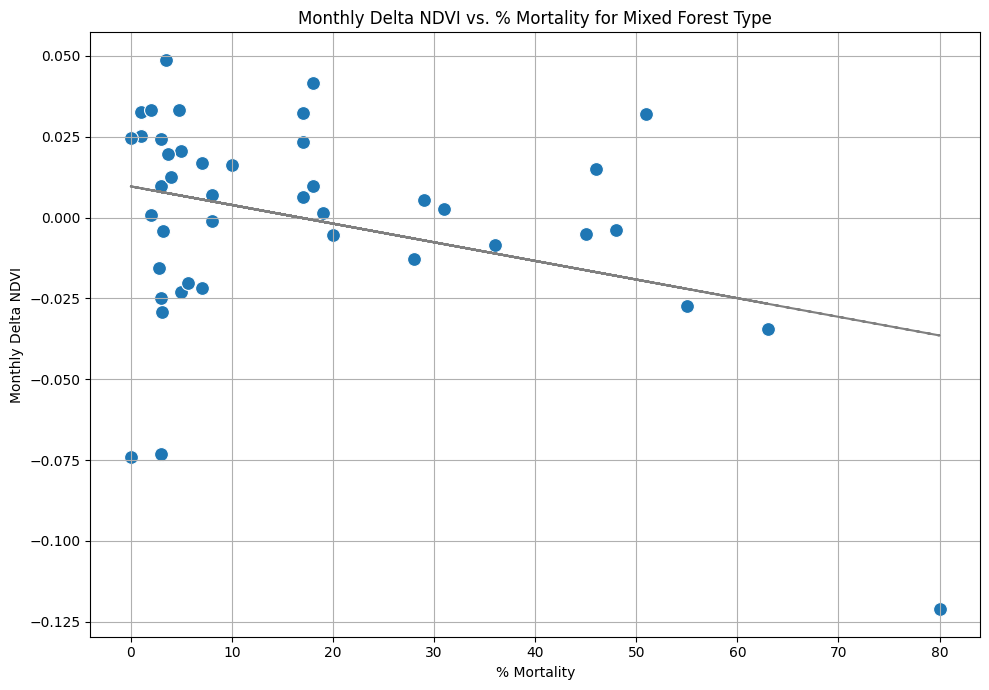

Plot saved to: /content/drive/MyDrive/New plots/Conifer_monthly_delta_ndvi_mortality.png


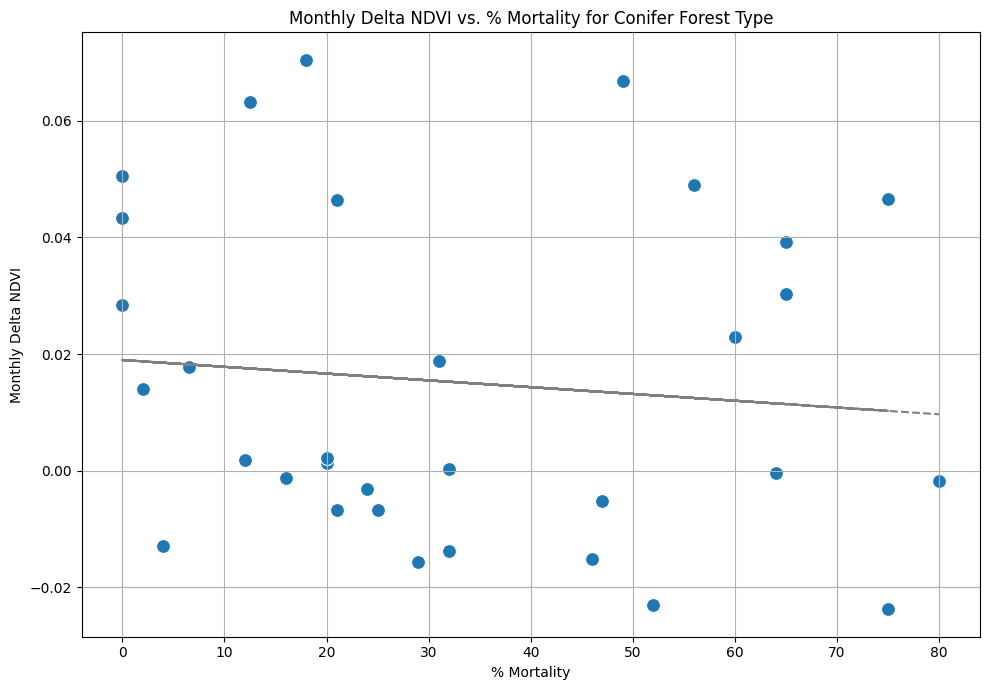

Plot saved to: /content/drive/MyDrive/New plots/Deciduous_monthly_delta_ndvi_mortality.png


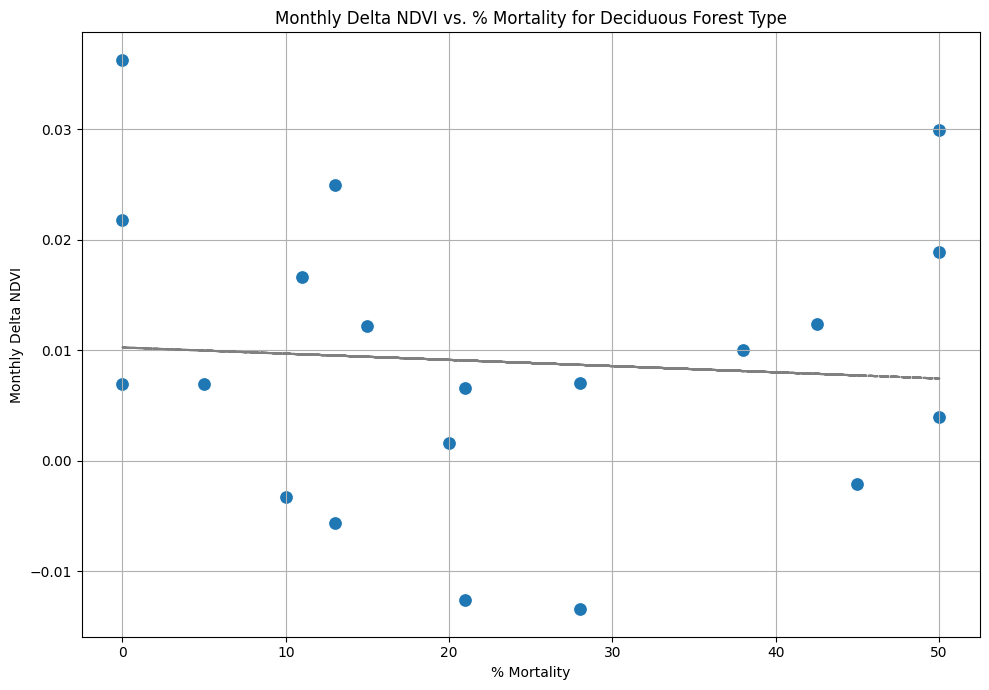

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import os

plot_output_dir = '/content/drive/MyDrive/New plots/'
os.makedirs(plot_output_dir, exist_ok=True)

unique_forest_types = merged_analysis_df['Forest_type'].dropna().unique()

for forest_type in unique_forest_types:
    plt.figure(figsize=(10, 7))
    subset_df = merged_analysis_df[merged_analysis_df['Forest_type'] == forest_type]

    if not subset_df.empty:
        sns.scatterplot(
            data=subset_df,
            x='%_Mort',
            y='delta_monthly',
            s=100
        )

        # Fit a linear regression model for the subset
        X_subset = subset_df[['%_Mort']]
        y_subset = subset_df['delta_monthly']

        # Only fit and plot regression if there's enough data
        if len(X_subset) > 1 and not X_subset.isnull().any().any() and not y_subset.isnull().any():
            model_subset = LinearRegression()
            model_subset.fit(X_subset, y_subset)
            plt.plot(X_subset, model_subset.predict(X_subset), color='gray', linestyle='--', label='Regression Line')
        elif len(X_subset) == 1:
            # If only one point, regression line is not meaningful, but can show the point
            pass
        else:
            print(f"Not enough data to fit a regression line for {forest_type}.")

        plt.title(f'Monthly Delta NDVI vs. % Mortality for {forest_type} Forest Type')
        plt.xlabel('% Mortality')
        plt.ylabel('Monthly Delta NDVI')
        plt.grid(True)
        plt.tight_layout()

        file_name = f"{forest_type.replace(' ', '_')}_monthly_delta_ndvi_mortality.png"
        save_path = os.path.join(plot_output_dir, file_name)
        plt.savefig(save_path)
        print(f"Plot saved to: {save_path}")
        plt.show()
    else:
        print(f"No data available for Forest Type: {forest_type}")

#### Identifying Anomalous Sites (Mixed Forest Type with Positive Residuals)

Based on the plot, we can now identify sites that are of 'mixed forest_type' and exhibit a 'positive residual' (meaning their `delta_monthly` is higher than predicted by the regression line).

In [20]:
# Calculate residuals
merged_analysis_df['predicted_delta_monthly'] = model.predict(merged_analysis_df[['%_Mort']])
merged_analysis_df['residual'] = merged_analysis_df['delta_monthly'] - merged_analysis_df['predicted_delta_monthly']

# Identify anomalous sites: mixed forest_type and positive residual
anomalous_sites_monthly = merged_analysis_df[
    (merged_analysis_df['Forest_type'] == 'mixed') &
    (merged_analysis_df['residual'] > 0)
]

print("Anomalous Sites (Mixed Forest Type, Positive Residuals) with Monthly NDVI:")
display(anomalous_sites_monthly[['plot_id', 'delta_monthly', '%_Mort', 'Forest_type', 'residual']])

Anomalous Sites (Mixed Forest Type, Positive Residuals) with Monthly NDVI:


,plot_id,delta_monthly,%_Mort,Forest_type,residual
